In [3]:
import pandas as pd
import xarray as xr
import numpy as np
import pandas as pd
import os

filedir = '/glade/campaign/cesm/cesmdata/inputdata/lnd/clm2/paramdata'
params = xr.open_dataset(filedir + "/clm50_params.c240207b.nc")

In [4]:
#variables from parameter file 
fnps       = float(params['fnps'])                    # frac light → non-photosynthetic pigment
theta_psii = float(params['theta_psii'])              # e-transport curvature
cp25_ppm   = float(params['cp25_yr2000']) * 1e6       # CO2 compensation point (mol/mol → ppm)
fnr        = float(params['fnr'])                     # gRubisco / gN(Rubisco)
act25      = float(params['act25'])                   # μmol CO2 / (gRubisco s)

pftnames = [''.join(row.astype(str)).strip() for row in params['pftname'].values]
c3psn    = params['c3psn'].values
flnr     = params['flnr'].values    # fraction leaf N in Rubisco
leafcn   = params['leafcn'].values  # gC/gN
slatop   = params['slatop'].values  # m²/gC

In [6]:
# Vcmax25top per PFT — derived from leaf N parameters
# N_area [gN/m²] = 1 / (leafcn [gC/gN] × slatop [m²/gC])
N_area     = 1.0 / (leafcn * slatop)
vcmax25top = flnr * N_area * fnr * act25    # μmol CO2/m²/s

# Jmax25top — CLM5 standard ratio (Medlyn et al. 2002)
jmax25top  = vcmax25top * 1.97

/glade/derecho/scratch/brendanc/tmp/ipykernel_46714/447005821.py:3: RuntimeWarning: divide by zero encountered in divide
  N_area     = 1.0 / (leafcn * slatop)
/glade/derecho/scratch/brendanc/tmp/ipykernel_46714/447005821.py:4: RuntimeWarning: invalid value encountered in multiply
  vcmax25top = flnr * N_area * fnr * act25    # μmol CO2/m²/s


In [7]:
# Hardcoded in PhotosynthesisMod.F90 
qe_c4 = 0.05    # C4 quantum efficiency mol CO2/mol photon (line 1508)
                 # used as: aj = qe * par_z * 4.6 = qe * PPFD (line 2631)

In [46]:
# Identify PFTs by exact name 
c3_i  = next(i for i, n in enumerate(pftnames) if n == 'c3_non-arctic_grass')
c4_i  = next(i for i, n in enumerate(pftnames) if n == 'c4_grass')
bdt_i = next(i for i, n in enumerate(pftnames) if n == 'broadleaf_deciduous_temperate_tree')
net_i = next(i for i, n in enumerate(pftnames) if n == 'needleleaf_evergreen_temperate_tree')

# Light response curves
PPFD  = np.linspace(0, 2200, 1000)
ci_c3 = 400.0 * 0.7
qabs  = 0.5 * (1.0 - fnps) * PPFD

def aj_c3_curve(pft_i):
    Jmax = jmax25top[pft_i]
    disc = (qabs + Jmax)**2 - 4.0 * theta_psii * qabs * Jmax
    je   = (qabs + Jmax - np.sqrt(np.maximum(disc, 0.0))) / (2.0 * theta_psii)
    aj   = je * (ci_c3 - cp25_ppm) / (4.0 * ci_c3 + 8.0 * cp25_ppm)
    return np.minimum(aj, vcmax25top[pft_i])

qy_c3 = 0.5 * (1.0 - fnps) * (ci_c3 - cp25_ppm) / (4.0 * ci_c3 + 8.0 * cp25_ppm)
qy_c4 = qe_c4

curves = {
    'C3 grass': (aj_c3_curve(c3_i),                              qy_c3,  '#2a78d6', '-'),
    'C4 grass': (np.minimum(qe_c4 * PPFD, vcmax25top[c4_i]),     qy_c4,  '#eda100', '--'),
    'BDT tree': (aj_c3_curve(bdt_i),                             qy_c3,  '#1baf7a', '-'),
    'NET tree': (aj_c3_curve(net_i),                             qy_c3,  '#e34948', '-'),
}

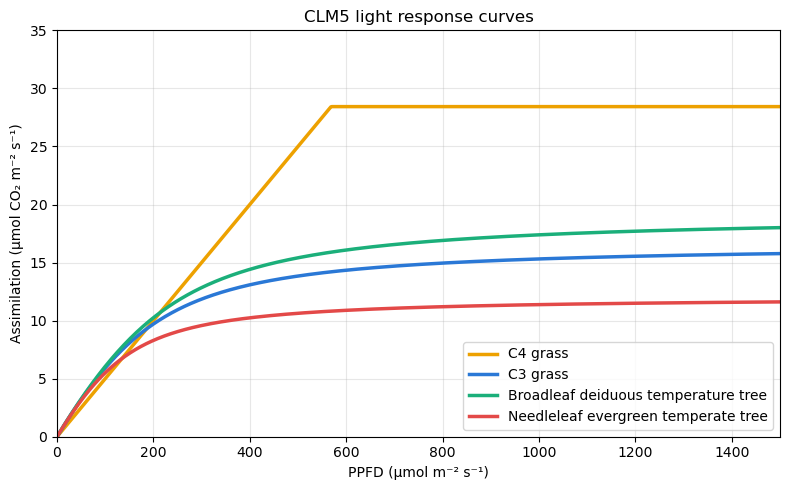

In [50]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(PPFD, aj_c4c,             color='#eda100', lw=2.5,
        label=f'C4 grass')
ax.plot(PPFD, aj_c3c,             color='#2a78d6', lw=2.5,
        label=f'C3 grass')
ax.plot(PPFD, aj_c3_curve(bdt_i), color='#1baf7a', lw=2.5,
        label=f'Broadleaf deiduous temperature tree')
ax.plot(PPFD, aj_c3_curve(net_i), color='#e34948', lw=2.5,
        label=f'Needleleaf evergreen temperate tree')

ppfd_t = np.array([0.0, 2200 * 0.25])

ax.set_xlim(0, 1500)
ax.set_xlabel('PPFD (μmol m⁻² s⁻¹)')
ax.set_ylabel('Assimilation (μmol CO₂ m⁻² s⁻¹)')
ax.set_title('CLM5 light response curves')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim([0, 35])

plt.tight_layout()
savedir = "/glade/derecho/scratch/brendanc/fates_output/radiation"
plt.savefig(f"{savedir}/CLM_light_curves.png", dpi=600, bbox_inches="tight")